In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder
from data_loader import *
from sklearn.metrics import roc_curve, auc
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict
from xgboost import XGBClassifier

# XGBoost

# Expert + Chen features for surfactants

In [2]:
visco = load_cleaned()
visco = drop_rheological(visco)
visco = add_expert_chen(visco, columns=['smiles_surfactant1', 'smiles_surfactant2'])
visco = drop_smiles(visco)
visco.info()

<class 'pandas.DataFrame'>
RangeIndex: 8152 entries, 0 to 8151
Data columns (total 54 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   id_surfactant1                      8152 non-null   str    
 1   type_surfactant1                    8152 non-null   str    
 2   c_surfactant1                       8152 non-null   float64
 3   id_surfactant2                      8152 non-null   str    
 4   type_surfactant2                    8152 non-null   str    
 5   c_surfactant2                       8152 non-null   float64
 6   id_additive1                        8152 non-null   str    
 7   c_additive1                         8152 non-null   float64
 8   id_additive2                        8152 non-null   str    
 9   c_additive2                         8152 non-null   float64
 10  temperature                         8152 non-null   int64  
 11  viscoelasticity                     8152 non-null   fl

In [3]:
y = visco['viscoelasticity']
X = visco.drop(columns=['viscoelasticity'])
X = drop_ids(X)
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 8152 entries, 0 to 8151
Data columns (total 49 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   type_surfactant1                    8152 non-null   str    
 1   c_surfactant1                       8152 non-null   float64
 2   type_surfactant2                    8152 non-null   str    
 3   c_surfactant2                       8152 non-null   float64
 4   c_additive1                         8152 non-null   float64
 5   c_additive2                         8152 non-null   float64
 6   temperature                         8152 non-null   int64  
 7   surfactant1_chen_MolLogP            8152 non-null   float64
 8   surfactant1_chen_Chi1v              8152 non-null   float64
 9   surfactant1_chen_VSA_EState7        8152 non-null   float64
 10  surfactant1_chen_VSA_EState8        8152 non-null   float64
 11  surfactant1_chen_qed                8152 non-null   fl

In [4]:
groups = visco[['id_surfactant1', 'id_surfactant2', 'id_additive1', 'id_additive2']].apply(tuple, axis=1)

cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)

categorical_features = ['type_surfactant1', 'type_surfactant2']
numerical_features = []

for column in X.columns:
    if X[column].dtype in ('float64', 'int64'):
        numerical_features.append(column)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(), categorical_features)
    ]
)

classifier = XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method='predict_proba')[:, 1]
fpr, tpr, thresholds = roc_curve(y, y_proba)
roc_auc = auc(fpr, tpr)

print(f"AUC: {roc_auc:.3f}")

AUC: 0.846


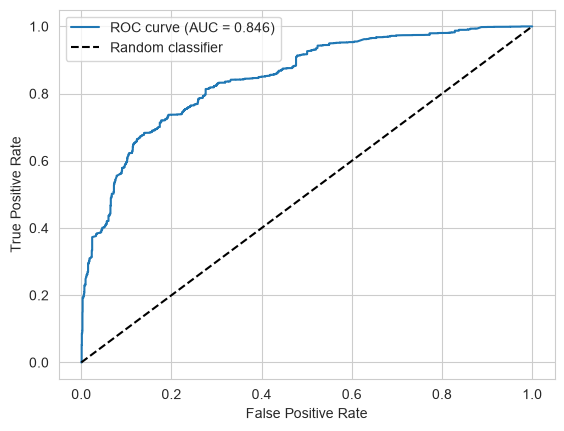

In [5]:
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

In [6]:
cv = StratifiedGroupKFold(n_splits=10, shuffle=True)

classifier = XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        objective="binary:logistic",
        eval_metric="logloss",
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

aucs = []
for _ in range(10):
    y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method='predict_proba')[:, 1]
    fpr, tpr, thresholds = roc_curve(y, y_proba)
    roc_auc = auc(fpr, tpr)
    aucs.append(roc_auc)
    print(f"AUC: {roc_auc:.3f}")

mean_auc = np.mean(aucs)
std_auc = np.std(aucs, ddof=1)
print(f"Mean: {mean_auc:.4f}")
print(f"Std:   {std_auc:.4f}")

AUC: 0.848
AUC: 0.845
AUC: 0.843
AUC: 0.842
AUC: 0.849
AUC: 0.845
AUC: 0.847
AUC: 0.860
AUC: 0.840
AUC: 0.842
Mean: 0.8460
Std:   0.0056


# Expert + Chen features for all compounds

In [7]:
visco = load_cleaned()
visco = drop_rheological(visco)
visco = add_expert_chen(visco, columns=['smiles_surfactant1', 'smiles_surfactant2', 'smiles_additive1', 'smiles_additive2'])
visco = drop_smiles(visco)
visco.info()

<class 'pandas.DataFrame'>
RangeIndex: 8152 entries, 0 to 8151
Data columns (total 96 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   id_surfactant1                      8152 non-null   str    
 1   type_surfactant1                    8152 non-null   str    
 2   c_surfactant1                       8152 non-null   float64
 3   id_surfactant2                      8152 non-null   str    
 4   type_surfactant2                    8152 non-null   str    
 5   c_surfactant2                       8152 non-null   float64
 6   id_additive1                        8152 non-null   str    
 7   c_additive1                         8152 non-null   float64
 8   id_additive2                        8152 non-null   str    
 9   c_additive2                         8152 non-null   float64
 10  temperature                         8152 non-null   int64  
 11  viscoelasticity                     8152 non-null   fl

In [8]:
y = visco['viscoelasticity']
X = visco.drop(columns=['viscoelasticity'])
X = drop_ids(X)
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 8152 entries, 0 to 8151
Data columns (total 96 columns):
 #   Column                              Non-Null Count  Dtype  
---  ------                              --------------  -----  
 0   id_surfactant1                      8152 non-null   str    
 1   type_surfactant1                    8152 non-null   str    
 2   c_surfactant1                       8152 non-null   float64
 3   id_surfactant2                      8152 non-null   str    
 4   type_surfactant2                    8152 non-null   str    
 5   c_surfactant2                       8152 non-null   float64
 6   id_additive1                        8152 non-null   str    
 7   c_additive1                         8152 non-null   float64
 8   id_additive2                        8152 non-null   str    
 9   c_additive2                         8152 non-null   float64
 10  temperature                         8152 non-null   int64  
 11  viscoelasticity                     8152 non-null   fl

In [9]:
groups = visco[['id_surfactant1', 'id_surfactant2', 'id_additive1', 'id_additive2']].apply(tuple, axis=1)

cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)

categorical_features = ['type_surfactant1', 'type_surfactant2']
numerical_features = []

for column in X.columns:
    if X[column].dtype in ('float64', 'int64'):
        numerical_features.append(column)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(), categorical_features)
    ]
)

classifier = XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method='predict_proba')[:, 1]
fpr, tpr, thresholds = roc_curve(y, y_proba)
roc_auc = auc(fpr, tpr)

print(f"AUC: {roc_auc:.3f}")

AUC: 0.854


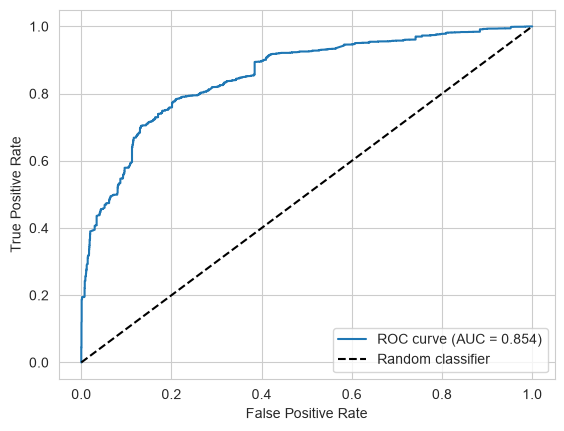

In [10]:
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

In [11]:
cv = StratifiedGroupKFold(n_splits=10, shuffle=True)

classifier = XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        objective="binary:logistic",
        eval_metric="logloss",
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

aucs = []
for _ in range(10):
    y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method='predict_proba')[:, 1]
    fpr, tpr, thresholds = roc_curve(y, y_proba)
    roc_auc = auc(fpr, tpr)
    aucs.append(roc_auc)
    print(f"AUC: {roc_auc:.3f}")

mean_auc = np.mean(aucs)
std_auc = np.std(aucs, ddof=1)
print(f"Mean: {mean_auc:.4f}")
print(f"Std:   {std_auc:.4f}")

AUC: 0.870
AUC: 0.865
AUC: 0.860
AUC: 0.862
AUC: 0.861
AUC: 0.864
AUC: 0.872
AUC: 0.872
AUC: 0.850
AUC: 0.872
Mean: 0.8647
Std:   0.0072


# Physiochemical features for surfactants

In [12]:
physio = load_cleaned()
physio = drop_rheological(physio)
physio = add_physiochemical(physio, columns=['smiles_surfactant1', 'smiles_surfactant2'])
physio = drop_smiles(physio)
physio.info()

<class 'pandas.DataFrame'>
RangeIndex: 8152 entries, 0 to 8151
Columns: 524 entries, id_surfactant1 to surfactant2_fp_255
dtypes: float64(517), int64(1), str(6)
memory usage: 32.6 MB


In [13]:
y = physio['viscoelasticity']
X = physio.drop(columns=['viscoelasticity'])
X = drop_ids(X)
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 8152 entries, 0 to 8151
Columns: 519 entries, type_surfactant1 to surfactant2_fp_255
dtypes: float64(516), int64(1), str(2)
memory usage: 32.3 MB


In [14]:
groups = physio[['id_surfactant1', 'id_surfactant2', 'id_additive1', 'id_additive2']].apply(tuple, axis=1)

cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)

categorical_features = ['type_surfactant1', 'type_surfactant2']
numerical_features = []

for column in X.columns:
    if X[column].dtype in ('float64', 'int64'):
        numerical_features.append(column)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(), categorical_features)
    ]
)

classifier = XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        objective="binary:logistic",
        eval_metric="logloss",
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method='predict_proba')[:, 1]
fpr, tpr, thresholds = roc_curve(y, y_proba)
roc_auc = auc(fpr, tpr)

print(f"AUC: {roc_auc:.3f}")

AUC: 0.865


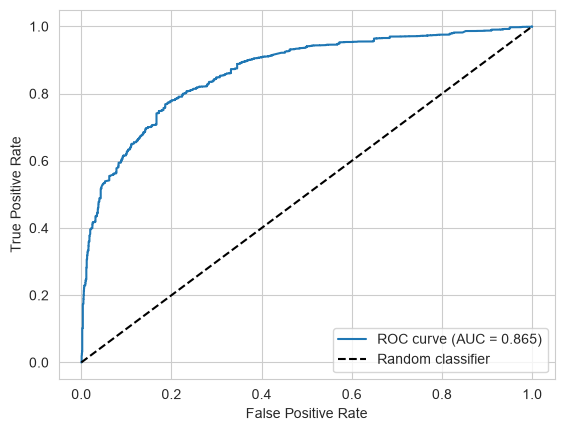

In [15]:
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

In [16]:
cv = StratifiedGroupKFold(n_splits=10, shuffle=True)

classifier = XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        objective="binary:logistic",
        eval_metric="logloss",
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

aucs = []
for _ in range(10):
    y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method='predict_proba')[:, 1]
    fpr, tpr, thresholds = roc_curve(y, y_proba)
    roc_auc = auc(fpr, tpr)
    aucs.append(roc_auc)
    print(f"AUC: {roc_auc:.3f}")

mean_auc = np.mean(aucs)
std_auc = np.std(aucs, ddof=1)
print(f"Mean: {mean_auc:.4f}")
print(f"Std:   {std_auc:.4f}")

AUC: 0.871
AUC: 0.860
AUC: 0.880
AUC: 0.862
AUC: 0.871
AUC: 0.861
AUC: 0.851
AUC: 0.870
AUC: 0.873
AUC: 0.867
Mean: 0.8667
Std:   0.0082


# Physiochemical features for all compounds

In [17]:
physio = load_cleaned()
physio = drop_rheological(physio)
physio = add_physiochemical(physio, columns=['smiles_surfactant1', 'smiles_surfactant2'])
physio = drop_smiles(physio)
physio.info()

<class 'pandas.DataFrame'>
RangeIndex: 8152 entries, 0 to 8151
Columns: 524 entries, id_surfactant1 to surfactant2_fp_255
dtypes: float64(517), int64(1), str(6)
memory usage: 32.6 MB


In [18]:
y = physio['viscoelasticity']
X = physio.drop(columns=['viscoelasticity'])
X = drop_ids(X)
X.info()

<class 'pandas.DataFrame'>
RangeIndex: 8152 entries, 0 to 8151
Columns: 519 entries, type_surfactant1 to surfactant2_fp_255
dtypes: float64(516), int64(1), str(2)
memory usage: 32.3 MB


In [19]:
groups = physio[['id_surfactant1', 'id_surfactant2', 'id_additive1', 'id_additive2']].apply(tuple, axis=1)

cv = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=42)

categorical_features = ['type_surfactant1', 'type_surfactant2']
numerical_features = []

for column in X.columns:
    if X[column].dtype in ('float64', 'int64'):
        numerical_features.append(column)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', numerical_features),
        ('cat', OneHotEncoder(), categorical_features)
    ]
)

classifier = XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        objective="binary:logistic",
        eval_metric="logloss",
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method='predict_proba')[:, 1]
fpr, tpr, thresholds = roc_curve(y, y_proba)
roc_auc = auc(fpr, tpr)

print(f"AUC: {roc_auc:.3f}")

AUC: 0.865


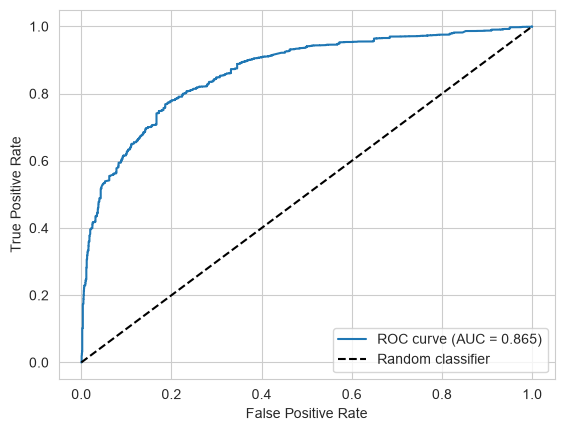

In [20]:
plt.plot(fpr, tpr, label=f"ROC curve (AUC = {roc_auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.show()

In [21]:
cv = StratifiedGroupKFold(n_splits=10, shuffle=True)

classifier = XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        objective="binary:logistic",
        eval_metric="logloss",
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", classifier)
])

aucs = []
for _ in range(10):
    y_proba = cross_val_predict(model, X, y, groups=groups, cv=cv, method='predict_proba')[:, 1]
    fpr, tpr, thresholds = roc_curve(y, y_proba)
    roc_auc = auc(fpr, tpr)
    aucs.append(roc_auc)
    print(f"AUC: {roc_auc:.3f}")

mean_auc = np.mean(aucs)
std_auc = np.std(aucs, ddof=1)
print(f"Mean: {mean_auc:.4f}")
print(f"Std:   {std_auc:.4f}")

AUC: 0.865
AUC: 0.852
AUC: 0.856
AUC: 0.844
AUC: 0.863
AUC: 0.856
AUC: 0.856
AUC: 0.863
AUC: 0.863
AUC: 0.861
Mean: 0.8580
Std:   0.0064
